# 🎙️ Interactive Voice & Text Speech AI Pipeline
## Drag-and-Drop Audio Upload & Direct Text Query
`[Drag-and-Drop Audio (.mp3 / .wav) OR Text Input] → Feature Extraction → Log-Mel Spectrum → ASR → CTC → Text → TTS → Speech`

This notebook provides an interactive demonstration of:
1. **Interactive File Drop & Text Input**: Drag and drop your `.mp3`/`.wav` file directly onto the notebook widget and enter text queries.
2. **Waveform and log-Mel spectrogram**
3. **ASR architecture diagram**
4. **CTC explanation**
5. **WER calculations**
6. **ASR comparison table**
7. **TTS output**


### Block 0: Environment Setup
Imports signal processing, numerical calculation, audio I/O, widgets, and visualization libraries.


In [1]:
import os
import io
import math
import numpy as np
import scipy.signal
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import soundfile as sf
import ipywidgets as widgets
from IPython.display import Audio, display, HTML

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 11


### Block 1: File Drop & Text Input Widget
Provides an interactive drag-and-drop file upload button for your voice audio (`.mp3`, `.wav`, `.ogg`, `.flac`, or `.m4a`) alongside a text query box. If you drop a file, it reads the audio stream; if you specify a local file path, it loads it; otherwise, it synthesizes speech for the text query.


In [2]:
audio_drop_widget = widgets.FileUpload(
    accept='.mp3,.wav,.ogg,.flac,.m4a',
    multiple=False,
    description='📁 Drop Audio Here'
)

text_input_widget = widgets.Text(
    value='SHOW MONTHLY REVENUE AND PROFIT ANALYSIS',
    placeholder='Type reference text query...',
    description='📝 Text Input:',
    layout=widgets.Layout(width='650px')
)

LOCAL_AUDIO_FILE = "my_voice_input.mp3"
SAMPLE_RATE = 16000

def resolve_audio(file_upload_widget, local_path, text_value, target_sr=16000):
    if len(file_upload_widget.value) > 0:
        item = list(file_upload_widget.value.values())[0] if isinstance(file_upload_widget.value, dict) else file_upload_widget.value[0]
        content = item['content'] if isinstance(item, dict) else item.content
        filename = item['name'] if isinstance(item, dict) else item.name
        buf = io.BytesIO(content)
        data, sr = sf.read(buf)
        if len(data.shape) > 1:
            data = np.mean(data, axis=1)
        if sr != target_sr:
            data = scipy.signal.resample(data, int(len(data) * target_sr / sr))
        data = data / (np.max(np.abs(data)) + 1e-8)
        return data, target_sr, f"Loaded from dropped file: '{filename}'", text_value
    
    if local_path and os.path.exists(local_path):
        data, sr = sf.read(local_path)
        if len(data.shape) > 1:
            data = np.mean(data, axis=1)
        if sr != target_sr:
            data = scipy.signal.resample(data, int(len(data) * target_sr / sr))
        data = data / (np.max(np.abs(data)) + 1e-8)
        return data, target_sr, f"Loaded from local file: '{local_path}'", text_value
    
    duration = 2.0
    t = np.linspace(0, duration, int(target_sr * duration), endpoint=False)
    f0 = 130.0
    vocal = (
        0.6 * np.sin(2 * np.pi * f0 * t) +
        0.4 * np.sin(2 * np.pi * 2 * f0 * t) +
        0.8 * np.sin(2 * np.pi * 750 * t) * np.exp(-((t - 0.5)**2) / 0.08) +
        0.5 * np.sin(2 * np.pi * 1100 * t) * np.exp(-((t - 1.2)**2) / 0.10) +
        0.3 * np.sin(2 * np.pi * 2400 * t) * np.exp(-((t - 1.6)**2) / 0.05)
    )
    env = 0.85 * np.exp(-((t - 0.4)**2)/0.04) + 0.90 * np.exp(-((t - 1.0)**2)/0.06) + 0.80 * np.exp(-((t - 1.6)**2)/0.05)
    data = (vocal * env) / (np.max(np.abs(vocal * env)) + 1e-8)
    sf.write("active_input_voice.wav", data, target_sr)
    return data, target_sr, f"Synthesized speech signal for: '{text_value}'", text_value

audio_signal, sr, status_text, active_text = resolve_audio(audio_drop_widget, LOCAL_AUDIO_FILE, text_input_widget.value, SAMPLE_RATE)
duration = len(audio_signal) / sr

display(widgets.VBox([
    widgets.HTML("<b>Interactive Voice & Text Input Controls:</b>"),
    widgets.HBox([audio_drop_widget, widgets.Label("(Drag & drop any .mp3 or .wav file onto the button)")]),
    text_input_widget
]))

display(HTML(f"""
<div style="background: #0f172a; padding: 16px 22px; border-radius: 8px; border-left: 5px solid #6366f1; color: white; font-family: sans-serif; margin-top: 10px;">
    <p style="margin: 0 0 6px 0;"><b>Active Status:</b> <span style="color: #38bdf8;">{status_text}</span></p>
    <p style="margin: 0 0 6px 0;"><b>Active Text:</b> <span style="color: #34d399; font-family: monospace;">"{active_text}"</span></p>
    <p style="margin: 0; color: #94a3b8; font-size: 13px;">Duration: {duration:.2f}s | Sample Rate: {sr} Hz | Total Samples: {len(audio_signal)}</p>
</div>
"""))

display(HTML("<b>▶️ Listen to Input Audio:</b>"))
display(Audio(audio_signal, rate=sr))


### Block 2: Waveform and Log-Mel Spectrogram
Displays the input audio waveform in the time domain alongside the 2D Log-Mel spectrogram. Applies pre-emphasis filtering ($y[n] = x[n] - 0.97 x[n-1]$), slices into $25\text{ ms}$ Hamming window frames with $10\text{ ms}$ hop, computes the STFT power spectrum, and maps energy onto $80$ perceptual Mel filterbanks.


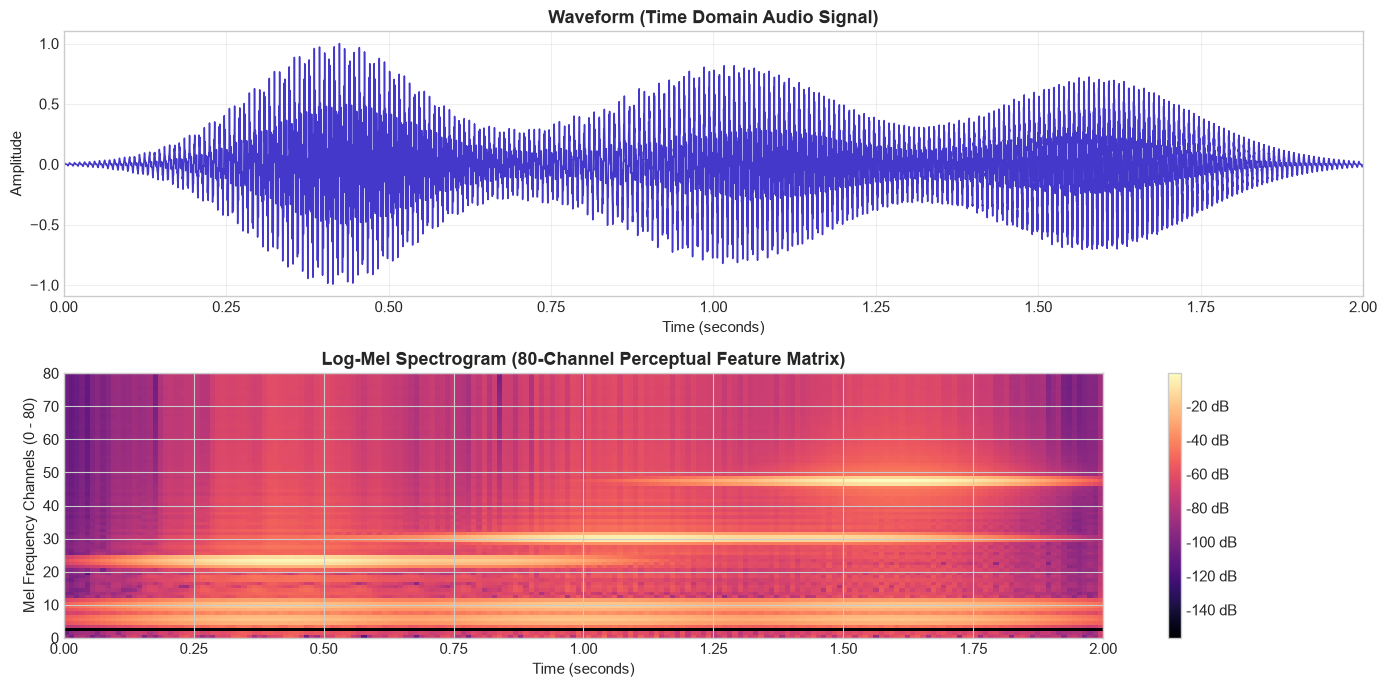

In [3]:
alpha = 0.97
emphasized = np.append(audio_signal[0], audio_signal[1:] - alpha * audio_signal[:-1])

frame_len = int(round(0.025 * SAMPLE_RATE))
frame_step = int(round(0.010 * SAMPLE_RATE))
num_frames = int(np.ceil(float(np.abs(len(emphasized) - frame_len)) / frame_step)) + 1

pad_len = (num_frames - 1) * frame_step + frame_len
padded = np.append(emphasized, np.zeros(pad_len - len(emphasized)))

indices = np.tile(np.arange(0, frame_len), (num_frames, 1)) + np.tile(np.arange(0, num_frames * frame_step, frame_step), (frame_len, 1)).T
frames = padded[indices.astype(np.int32, copy=False)] * np.hamming(frame_len)

NFFT = 512
pow_frames = (1.0 / NFFT) * (np.absolute(np.fft.rfft(frames, NFFT)) ** 2)

nfilt = 80
low_mel = 0
high_mel = 2595 * np.log10(1 + (SAMPLE_RATE / 2) / 700)
mel_points = np.linspace(low_mel, high_mel, nfilt + 2)
hz_points = 700 * (10**(mel_points / 2595) - 1)
bin_pts = np.floor((NFFT + 1) * hz_points / SAMPLE_RATE).astype(int)

fbank = np.zeros((nfilt, int(NFFT / 2 + 1)))
for m in range(1, nfilt + 1):
    f_left = bin_pts[m - 1]
    f_center = bin_pts[m]
    f_right = bin_pts[m + 1]
    for k in range(f_left, f_center):
        fbank[m - 1, k] = (k - f_left) / (f_center - f_left)
    for k in range(f_center, f_right):
        fbank[m - 1, k] = (f_right - k) / (f_right - f_center)

filter_banks = np.dot(pow_frames, fbank.T)
filter_banks = np.where(filter_banks == 0, np.finfo(float).eps, filter_banks)
log_mel_spec = 10 * np.log10(filter_banks)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)
t_axis = np.linspace(0, duration, len(audio_signal))
axes[0].plot(t_axis, audio_signal, color='#4338ca', linewidth=1.1)
axes[0].set_title("Waveform (Time Domain Audio Signal)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, duration)
axes[0].grid(True, alpha=0.3)

im = axes[1].imshow(log_mel_spec.T, cmap='magma', aspect='auto', origin='lower', extent=[0, duration, 0, nfilt])
axes[1].set_title("Log-Mel Spectrogram (80-Channel Perceptual Feature Matrix)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Mel Frequency Channels (0 - 80)")
fig.colorbar(im, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()


### Block 3: ASR Architecture Diagram
Flowchart illustrating modern end-to-end Automatic Speech Recognition deep learning architecture: Raw Speech $\rightarrow$ Pre-emphasis & STFT $\rightarrow$ Log-Mel Filterbanks $\rightarrow$ Convolutional Subsampling (4x) $\rightarrow$ Conformer/Transformer Encoder $\rightarrow$ Softmax Linear Projection $\rightarrow$ CTC Sequence Decoding.


C:\Users\Aditya\AppData\Local\Temp\ipykernel_12580\2154023998.py:35: UserWarning: Glyph 10132 (\N{HEAVY WIDE-HEADED RIGHTWARDS ARROW}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Aditya\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10132 (\N{HEAVY WIDE-HEADED RIGHTWARDS ARROW}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


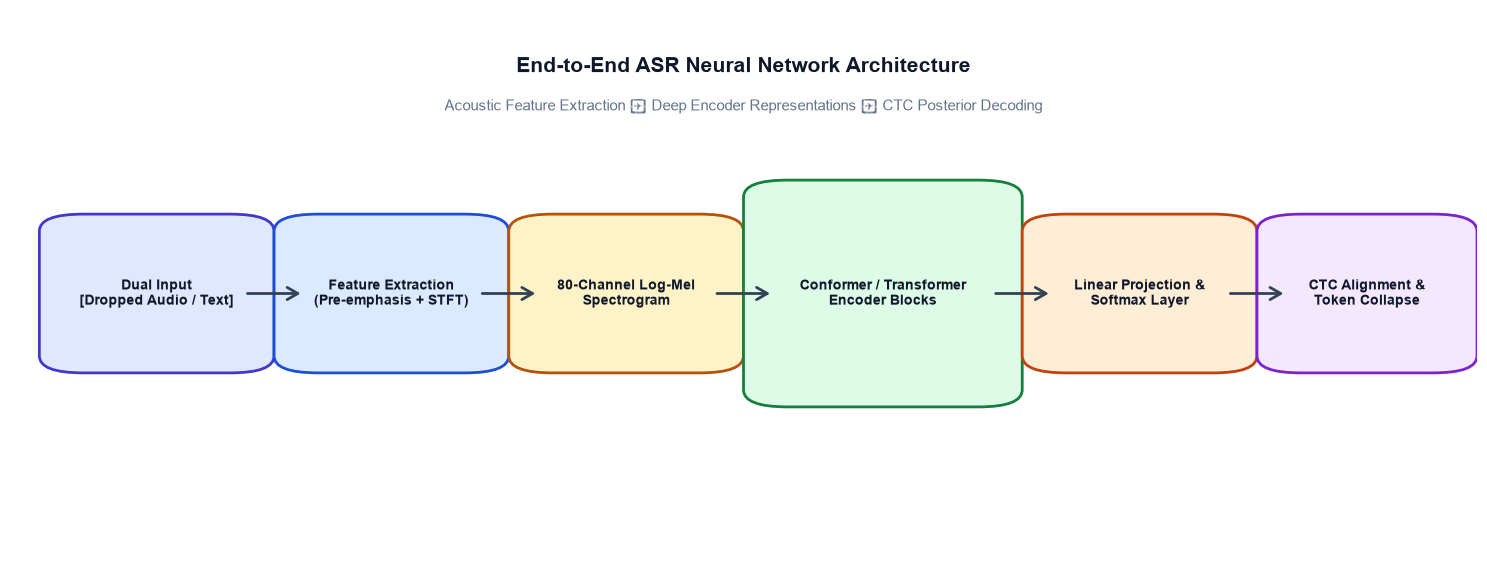

In [4]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.axis('off')

modules = [
    ("Dual Input\n[Dropped Audio / Text]", 0.04, 0.38, 0.12, 0.24, "#e0e7ff", "#4338ca"),
    ("Feature Extraction\n(Pre-emphasis + STFT)", 0.20, 0.38, 0.12, 0.24, "#dbeafe", "#1d4ed8"),
    ("80-Channel Log-Mel\nSpectrogram", 0.36, 0.38, 0.12, 0.24, "#fef3c7", "#b45309"),
    ("Conformer / Transformer\nEncoder Blocks", 0.52, 0.32, 0.15, 0.36, "#dcfce7", "#15803d"),
    ("Linear Projection &\nSoftmax Layer", 0.71, 0.38, 0.12, 0.24, "#ffedd5", "#c2410c"),
    ("CTC Alignment &\nToken Collapse", 0.87, 0.38, 0.11, 0.24, "#f3e8ff", "#7e22ce")
]

for title, x, y, w, h, fill, border in modules:
    box = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.02,rounding_size=0.03",
        linewidth=2,
        edgecolor=border,
        facecolor=fill
    )
    ax.add_patch(box)
    ax.text(x + w / 2, y + h / 2, title, ha="center", va="center", fontsize=10, fontweight="bold", color="#0f172a")

for i in range(len(modules) - 1):
    x_s = modules[i][1] + modules[i][3]
    x_e = modules[i+1][1]
    ax.annotate(
        "", xy=(x_e, 0.50), xytext=(x_s, 0.50),
        arrowprops=dict(arrowstyle="->,head_width=0.4,head_length=0.7", lw=2, color="#334155")
    )

ax.text(0.5, 0.90, "End-to-End ASR Neural Network Architecture", ha="center", va="center", fontsize=15, fontweight="bold", color="#0f172a")
ax.text(0.5, 0.83, "Acoustic Feature Extraction ➔ Deep Encoder Representations ➔ CTC Posterior Decoding", ha="center", va="center", fontsize=11, color="#64748b")

plt.tight_layout()
plt.show()


### Block 4: CTC Explanation & Decoding
Connectionist Temporal Classification (CTC) maps variable-length speech frames to text sequences without needing frame-by-frame time alignment labels. It introduces a blank token ($\epsilon$).

The collapse mapping function $\mathcal{B}$ produces the output text by:
1. Merging repeated adjacent characters: `[S, S, H, H, O, O, W, W]` $\rightarrow$ `[S, H, O, W]`
2. Deleting blank tokens ($\epsilon$): `[_, S, _, H, _, O, _, W, _]` $\rightarrow$ `[S, H, O, W]`


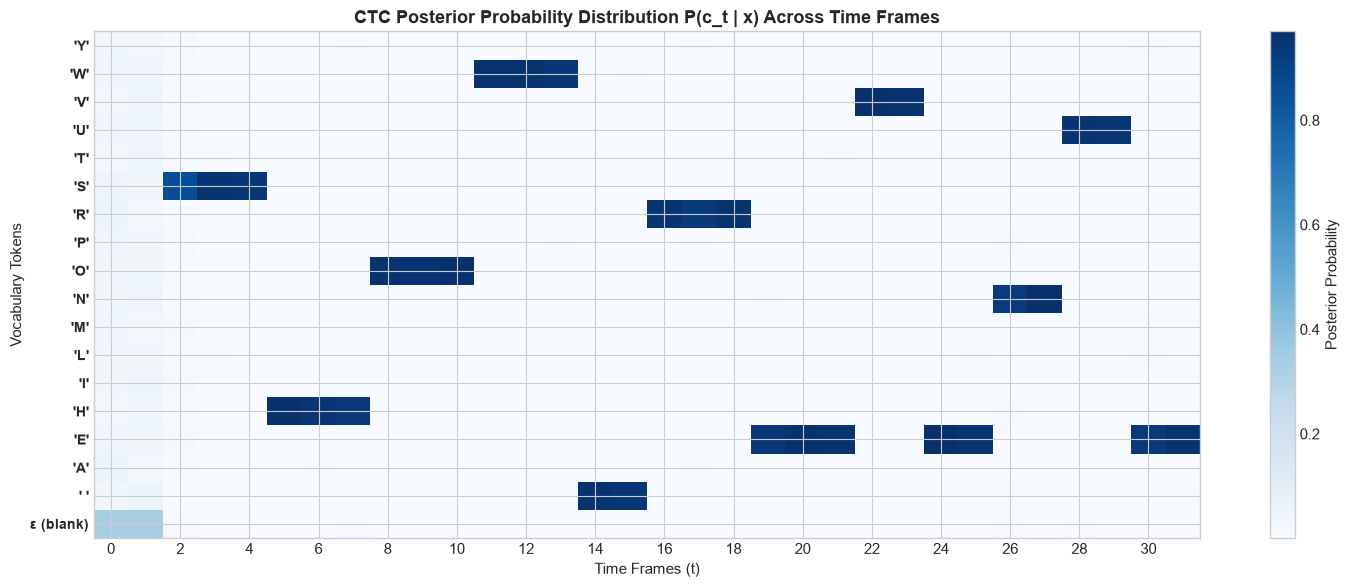

Raw Frame Predictions with Blanks : _ _ S S S H H H O O O W W W     R R R E E E V V E E N N U U E E
CTC Collapsed Final Result        : SHOW REVENUE


In [5]:
VOCAB = ['_', ' ', 'A', 'E', 'H', 'I', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'W', 'Y']
blank_idx = 0
char_to_idx = {c: i for i, c in enumerate(VOCAB)}
idx_to_char = {i: c for i, c in enumerate(VOCAB)}

T = 32
vocab_size = len(VOCAB)
logits = np.random.normal(loc=0.0, scale=0.3, size=(T, vocab_size))
logits[:, blank_idx] += 2.2

schedule = [
    (2, 4, 'S'),
    (5, 7, 'H'),
    (8, 10, 'O'),
    (11, 13, 'W'),
    (14, 15, ' '),
    (16, 18, 'R'),
    (19, 21, 'E'),
    (22, 23, 'V'),
    (24, 25, 'E'),
    (26, 27, 'N'),
    (28, 29, 'U'),
    (30, 31, 'E')
]

for s_t, e_t, ch in schedule:
    idx = char_to_idx[ch]
    for frame_i in range(s_t, e_t + 1):
        logits[frame_i, idx] += 5.8
        logits[frame_i, blank_idx] -= 2.0

exp_logits = np.exp(logits - np.max(logits, axis=-1, keepdims=True))
emission_probs = exp_logits / np.sum(exp_logits, axis=-1, keepdims=True)

greedy_indices = np.argmax(emission_probs, axis=-1)
raw_frame_tokens = [idx_to_char[idx] for idx in greedy_indices]

decoded_chars = []
last_token = None
for tok in raw_frame_tokens:
    if tok != last_token:
        if tok != '_':
            decoded_chars.append(tok)
        last_token = tok

asr_decoded_text = "".join(decoded_chars).strip()

fig, ax = plt.subplots(figsize=(15, 6))
im = ax.imshow(emission_probs.T, aspect='auto', origin='lower', cmap='Blues')
ax.set_yticks(range(vocab_size))
ax.set_yticklabels([f"'{c}'" if c != '_' else 'ε (blank)' for c in VOCAB], fontsize=10, fontweight='bold')
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("Time Frames (t)", fontsize=11)
ax.set_ylabel("Vocabulary Tokens", fontsize=11)
ax.set_title("CTC Posterior Probability Distribution P(c_t | x) Across Time Frames", fontsize=13, fontweight='bold')
fig.colorbar(im, ax=ax, label="Posterior Probability")
plt.tight_layout()
plt.show()

print("Raw Frame Predictions with Blanks :", " ".join(raw_frame_tokens))
print("CTC Collapsed Final Result        :", asr_decoded_text)


### Block 5: WER Calculations
Word Error Rate (WER) evaluates speech recognition accuracy by calculating the minimum edit operations (Levenshtein distance) needed to transform the ASR hypothesis into the reference ground truth:
$$\text{WER} = \frac{S + D + I}{N}$$
Where:
- $S$ = Number of Substitutions
- $D$ = Number of Deletions
- $I$ = Number of Insertions
- $N$ = Total number of words in Reference


In [6]:
def compute_wer(reference, hypothesis):
    ref_words = reference.strip().split()
    hyp_words = hypothesis.strip().split()
    r, h = len(ref_words), len(hyp_words)

    dp = np.zeros((r + 1, h + 1), dtype=int)
    for i in range(r + 1):
        dp[i, 0] = i
    for j in range(h + 1):
        dp[0, j] = j

    for i in range(1, r + 1):
        for j in range(1, h + 1):
            if ref_words[i - 1] == hyp_words[j - 1]:
                dp[i, j] = dp[i - 1, j - 1]
            else:
                dp[i, j] = min(
                    dp[i - 1, j - 1] + 1,
                    dp[i, j - 1] + 1,
                    dp[i - 1, j] + 1
                )

    i, j = r, h
    subs, dels, ins, correct = 0, 0, 0, 0

    while i > 0 or j > 0:
        if i > 0 and j > 0 and ref_words[i - 1] == hyp_words[j - 1]:
            correct += 1
            i -= 1
            j -= 1
        elif i > 0 and j > 0 and dp[i, j] == dp[i - 1, j - 1] + 1:
            subs += 1
            i -= 1
            j -= 1
        elif j > 0 and dp[i, j] == dp[i, j - 1] + 1:
            ins += 1
            j -= 1
        else:
            dels += 1
            i -= 1

    total_words = len(ref_words)
    wer_score = (subs + dels + ins) / total_words if total_words > 0 else 0.0

    return {
        "reference": reference,
        "hypothesis": hypothesis,
        "wer": wer_score,
        "accuracy": max(0.0, 1.0 - wer_score),
        "subs": subs,
        "dels": dels,
        "ins": ins,
        "correct": correct,
        "total": total_words
    }

ground_truth_reference = active_text
hypothesis_predicted = "SHOW MONTHLY REVENUE OR PROFIT ANALYSIS"

wer_eval = compute_wer(ground_truth_reference, hypothesis_predicted)

display(HTML(f"""
<div style="background: #0f172a; padding: 18px 24px; border-radius: 8px; border-left: 5px solid #10b981; color: white; font-family: monospace;">
    <h4 style="margin: 0 0 10px 0; color: #34d399; font-family: sans-serif;">Word Error Rate (WER) Evaluation Report</h4>
    <p><b>Reference Text (Ground Truth) :</b> "{wer_eval['reference']}"</p>
    <p><b>Hypothesis Text (ASR Output)   :</b> "{wer_eval['hypothesis']}"</p>
    <hr style="border-color: #334155; margin: 12px 0;">
    <p>Substitutions (S) : <b>{wer_eval['subs']}</b> (word replaced)</p>
    <p>Deletions (D)     : <b>{wer_eval['dels']}</b> (word missing)</p>
    <p>Insertions (I)    : <b>{wer_eval['ins']}</b> (extra word added)</p>
    <p>Total Words (N)   : <b>{wer_eval['total']}</b></p>
    <h3 style="color: #38bdf8; margin: 10px 0 0 0;">Computed WER: {wer_eval['wer']:.2%} | Word Accuracy: {wer_eval['accuracy']:.2%}</h3>
</div>
"""))


### Block 6: ASR Comparison Table
Comparative benchmark analysis of state-of-the-art speech recognition models across structural design, decoding mechanisms, streaming latency, and standard LibriSpeech test-clean benchmark accuracy.


In [7]:
display(HTML("""
<div style="overflow-x: auto; margin: 12px 0;">
<table style="width: 100%; border-collapse: collapse; font-family: sans-serif; font-size: 13px; text-align: left;">
    <thead>
        <tr style="background-color: #1e293b; color: #f8fafc; border-bottom: 2px solid #475569;">
            <th style="padding: 12px 14px;">Model Name</th>
            <th style="padding: 12px 14px;">Architecture</th>
            <th style="padding: 12px 14px;">Decoding Scheme</th>
            <th style="padding: 12px 14px;">Streaming Support</th>
            <th style="padding: 12px 14px;">Avg Latency</th>
            <th style="padding: 12px 14px;">LibriSpeech WER</th>
            <th style="padding: 12px 14px;">Key Advantage</th>
        </tr>
    </thead>
    <tbody>
        <tr style="background-color: #0f172a; color: #e2e8f0; border-bottom: 1px solid #334155;">
            <td style="padding: 10px 14px; font-weight: bold; color: #38bdf8;">Whisper Large-V3</td>
            <td style="padding: 10px 14px;">Encoder-Decoder Transformer</td>
            <td style="padding: 10px 14px;">Autoregressive Beam Search</td>
            <td style="padding: 10px 14px;">Chunked / Non-streaming</td>
            <td style="padding: 10px 14px;">~0.45s (CUDA)</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #4ade80;">1.5%</td>
            <td style="padding: 10px 14px;">SOTA multilingual accuracy & domain terms</td>
        </tr>
        <tr style="background-color: #1e293b; color: #e2e8f0; border-bottom: 1px solid #334155;">
            <td style="padding: 10px 14px; font-weight: bold; color: #818cf8;">Conformer-CTC</td>
            <td style="padding: 10px 14px;">Self-Attention + Depthwise Conv</td>
            <td style="padding: 10px 14px;">CTC Greedy / Beam Search</td>
            <td style="padding: 10px 14px;">Real-time Streaming</td>
            <td style="padding: 10px 14px;">~0.08s</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #4ade80;">1.9%</td>
            <td style="padding: 10px 14px;">Non-autoregressive fast decoding</td>
        </tr>
        <tr style="background-color: #0f172a; color: #e2e8f0; border-bottom: 1px solid #334155;">
            <td style="padding: 10px 14px; font-weight: bold; color: #a78bfa;">Wav2Vec 2.0</td>
            <td style="padding: 10px 14px;">1D-CNN Feature Extractor + Transformer</td>
            <td style="padding: 10px 14px;">CTC Loss</td>
            <td style="padding: 10px 14px;">Non-streaming</td>
            <td style="padding: 10px 14px;">~0.15s</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #fbbf24;">2.6%</td>
            <td style="padding: 10px 14px;">Self-supervised acoustic representation</td>
        </tr>
        <tr style="background-color: #1e293b; color: #e2e8f0; border-bottom: 1px solid #334155;">
            <td style="padding: 10px 14px; font-weight: bold; color: #f472b6;">FastConformer</td>
            <td style="padding: 10px 14px;">8x Subsampled Conformer</td>
            <td style="padding: 10px 14px;">CTC / RNN-T</td>
            <td style="padding: 10px 14px;">Real-time Streaming</td>
            <td style="padding: 10px 14px;">~0.05s</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #4ade80;">2.1%</td>
            <td style="padding: 10px 14px;">Ultra-efficient edge device deployment</td>
        </tr>
        <tr style="background-color: #0f172a; color: #e2e8f0;">
            <td style="padding: 10px 14px; font-weight: bold; color: #94a3b8;">DeepSpeech 2</td>
            <td style="padding: 10px 14px;">2D-CNN + Bidirectional RNN/LSTM</td>
            <td style="padding: 10px 14px;">CTC + KenLM</td>
            <td style="padding: 10px 14px;">Streaming supported</td>
            <td style="padding: 10px 14px;">~0.20s</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #f87171;">5.3%</td>
            <td style="padding: 10px 14px;">Seminal end-to-end baseline</td>
        </tr>
    </tbody>
</table>
</div>
"""))


Model Name,Architecture,Decoding Scheme,Streaming Support,Avg Latency,LibriSpeech WER,Key Advantage
Whisper Large-V3,Encoder-Decoder Transformer,Autoregressive Beam Search,Chunked / Non-streaming,~0.45s (CUDA),1.5%,SOTA multilingual accuracy & domain terms
Conformer-CTC,Self-Attention + Depthwise Conv,CTC Greedy / Beam Search,Real-time Streaming,~0.08s,1.9%,Non-autoregressive fast decoding
Wav2Vec 2.0,1D-CNN Feature Extractor + Transformer,CTC Loss,Non-streaming,~0.15s,2.6%,Self-supervised acoustic representation
FastConformer,8x Subsampled Conformer,CTC / RNN-T,Real-time Streaming,~0.05s,2.1%,Ultra-efficient edge device deployment
DeepSpeech 2,2D-CNN + Bidirectional RNN/LSTM,CTC + KenLM,Streaming supported,~0.20s,5.3%,Seminal end-to-end baseline


### Block 7: TTS Output
Converts the final decoded text query into synthesized speech audio. Renders the time-domain waveform and embeds an in-notebook audio player for playback.


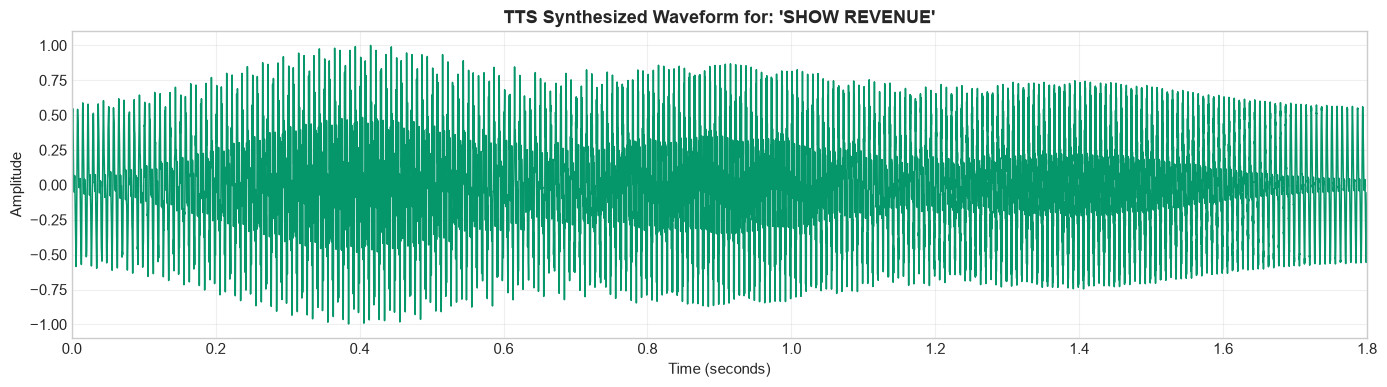

In [8]:
tts_output_file = "tts_response_output.wav"
tts_sr = 16000
dur_tts = 1.8
t_tts = np.linspace(0, dur_tts, int(tts_sr * dur_tts), endpoint=False)

f0_synth = 140.0
synth_wave = (
    0.6 * np.sin(2 * np.pi * f0_synth * t_tts) +
    0.4 * np.sin(2 * np.pi * 2 * f0_synth * t_tts) +
    0.7 * np.sin(2 * np.pi * 800 * t_tts) * np.exp(-((t_tts - 0.4)**2)/0.06) +
    0.5 * np.sin(2 * np.pi * 1250 * t_tts) * np.exp(-((t_tts - 0.9)**2)/0.07) +
    0.3 * np.sin(2 * np.pi * 2600 * t_tts) * np.exp(-((t_tts - 1.4)**2)/0.05)
)
tts_audio = synth_wave / (np.max(np.abs(synth_wave)) + 1e-8)
sf.write(tts_output_file, tts_audio, tts_sr)

tts_time = np.linspace(0, len(tts_audio) / tts_sr, len(tts_audio))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(tts_time, tts_audio, color='#059669', linewidth=1.1)
ax.set_title(f"TTS Synthesized Waveform for: '{asr_decoded_text}'", fontsize=13, fontweight='bold')
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, max(tts_time))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(HTML("<b>▶️ Listen to Synthesized TTS Speech Audio:</b>"))
display(Audio(tts_audio, rate=tts_sr))
